# 1. 픽셀 및 색상 채널 처리

사진을 이루는 작은 색 타일인 **픽셀**을 숫자로 읽고, 색 표현을 바꾸고, 채널을 나누어 다시 합쳐 본다. 사용자가 제공한 레나 영상을 사용한다.

노트북과 `assets` 폴더를 같은 위치에 두고 코드 셀을 위에서부터 실행한다. 필요한 패키지는 `opencv-python`, `numpy`, `matplotlib`이다.

## 1.1 픽셀과 영상 배열

### 픽셀은 작은 색 타일

- 사진을 아주 크게 확대하면 작은 칸들이 모여 있다. 이 칸이 **픽셀**이다.
- 컴퓨터는 각 칸의 밝기나 색을 숫자로 저장한다.
- 그레이스케일 영상은 보통 한 픽셀에 숫자 하나를 저장한다.
- 컬러 영상은 보통 한 픽셀에 색 성분 세 개를 저장한다.
- 이 문서의 실습은 **8비트 unsigned 정수인 `uint8` 영상**을 사용한다. 다른 자료형의 영상도 존재한다.

| 8비트 그레이스케일 값 | 보이는 밝기 |
| :---: | :---: |
| 0 | 검정 |
| 128 | 중간 회색 |
| 255 | 흰색 |

$$
0 \le I[y,x] \le 255
$$

여기서 $I$는 그레이스케일 배열이고, $x$는 가로 위치, $y$는 세로 위치다.

### 좌표와 배열 모양

- 영상의 왼쪽 위가 $(x,y)=(0,0)$이다.
- 오른쪽으로 갈수록 $x$, 아래로 갈수록 $y$가 증가한다.
- 좌표는 보통 `(x, y)`로 말하지만 **NumPy 배열은 `[y, x]`로 접근**한다.

$$
\text{컬러 배열 모양}=(H,W,3),\qquad
\text{그레이스케일 배열 모양}=(H,W)
$$

| 코드 | 뜻 |
| :---: | :---: |
| `img.shape` | 높이, 너비, 채널 수 |
| `img.dtype` | 숫자를 저장하는 자료형 |
| `img[y, x]` | 한 픽셀의 BGR 값 |
| `img[y, x, 0]` | 그 픽셀의 B 값 |
| `img[y1:y2, x1:x2]` | 직사각형 영역 선택, 끝 인덱스는 제외 |



> [!warning] 원본을 바꾸고 싶지 않을 때
> NumPy 슬라이싱으로 얻은 영역은 원본과 메모리를 공유할 수 있다. 독립적으로 수정하려면 `.copy()`를 사용한다.

OpenCV: 5.0.0
shape: (250, 250, 3) dtype: uint8
(x, y): (120, 120) BGR: [125, 130, 205]


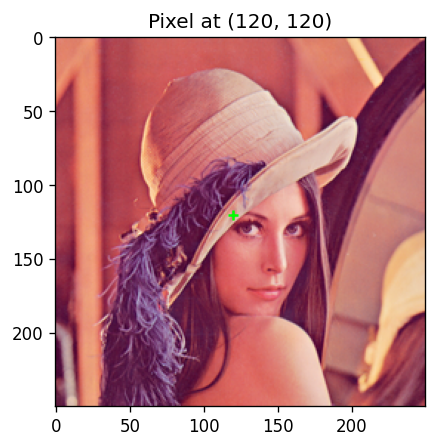

In [1]:
# 셀 1: 영상 불러오기와 픽셀 확인
# BGR 순서로 읽은 배열에서 [y, x] 위치의 값을 확인하고 RGB로 표시한다.

# Path는 운영체제에 맞게 파일 경로를 조합하는 데 사용한다.
from pathlib import Path
# OpenCV는 영상 처리, NumPy는 배열 계산, Matplotlib은 결과 시각화에 사용한다.
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 현재 작업 폴더를 기준으로 assets를 찾는다. 노트북은 각 장의 폴더에서 실행한다.
ROOT = Path.cwd()
ASSETS = ROOT / 'assets'
path = ASSETS / 'Lenna.png'
if not path.exists():
    raise FileNotFoundError('노트북과 같은 폴더의 assets/Lenna.png를 확인하세요.')
# 파일을 바이트 배열로 읽어 디코딩한다. IMREAD_COLOR의 결과는 BGR 순서다.
img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
if img is None:
    raise ValueError('이미지 디코딩 실패')

# 비교 그림의 배치를 통일하고, 영상 또는 결과 배열을 화면에 표시한다.
def panel(items, cols=3):
    rows = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows), squeeze=False)
    for ax, (title, image) in zip(axes.flat, items):
        if image.ndim == 2:
            ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(image)
        ax.set_title(title)
        ax.axis('off')
    for ax in list(axes.flat)[len(items):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()

# shape는 (높이, 너비) 순서다. 좌표 (x, y)로 읽을 때는 배열 인덱스 [y, x]와 구분한다.
h, w = img.shape[:2]
x, y = 120, 120
print('OpenCV:', cv2.__version__)
print('shape:', img.shape, 'dtype:', img.dtype)
print('(x, y):', (x, y), 'BGR:', img[y, x].tolist())
plt.figure(figsize=(4, 4))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.scatter([x], [y], c='lime', marker='+')
plt.title('Pixel at (120, 120)')
plt.show()

### 실제 픽셀 확대

- 색을 밝기 하나로 바꾼 뒤 8×8 영역을 확대한다. 그레이스케일 변환식은 1.2에서 살펴본다.
- 숫자가 클수록 밝다. 확대 그림의 한 칸이 원본의 픽셀 하나다.
- `120:128`은 120부터 127까지이며, 끝값 128은 포함하지 않는다.

Gray at (120, 120): 152


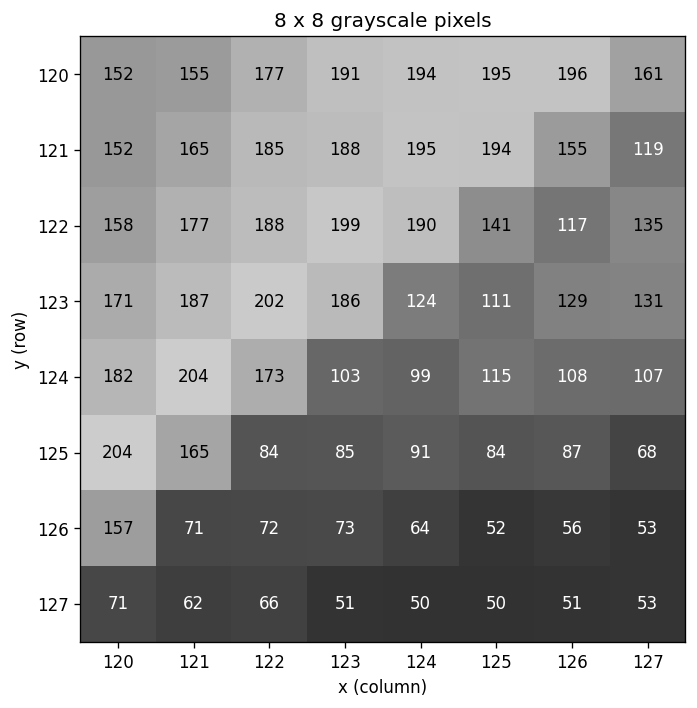

In [2]:
# 셀 2: 8×8 픽셀 영역 확대
# 그레이스케일 값은 0~255로 표시하며, 배열의 끝 인덱스는 포함하지 않는다.

# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# 선택 영역을 독립 사본으로 만들어 원본과의 메모리 공유를 끊는다.
patch = gray[y:y+8, x:x+8].copy()
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(patch, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
for row in range(8):
    for col in range(8):
        value = int(patch[row, col])
        ax.text(col, row, str(value), ha='center', va='center',
                color='white' if value < 128 else 'black')
ax.set_xticks(range(8), range(x, x+8))
ax.set_yticks(range(8), range(y, y+8))
ax.set_xlabel('x (column)')
ax.set_ylabel('y (row)')
ax.set_title('8 x 8 grayscale pixels')
fig.tight_layout()
plt.show()
print('Gray at (120, 120):', int(gray[y, x]))

### 밝기 계산에서 넘침 방지하기

밝기를 30 올리되 255를 넘지 않도록 한다.

$$
I_{\mathrm{out}}=\min(255,\max(0,I_{\mathrm{in}}+30))
$$



- `uint8` 배열에 NumPy로 그대로 덧셈하면 범위를 넘은 값이 순환할 수 있다.
- 먼저 넓은 정수형으로 계산하고, 값을 제한한 뒤 `uint8`로 되돌린다.
- 컬러 채널 각각에 같은 값을 더하는 간단한 실습이며, 지각적으로 균일한 밝기 조절을 뜻하지는 않는다.

uint8 240 + 30: [14]
범위 제한: [255]


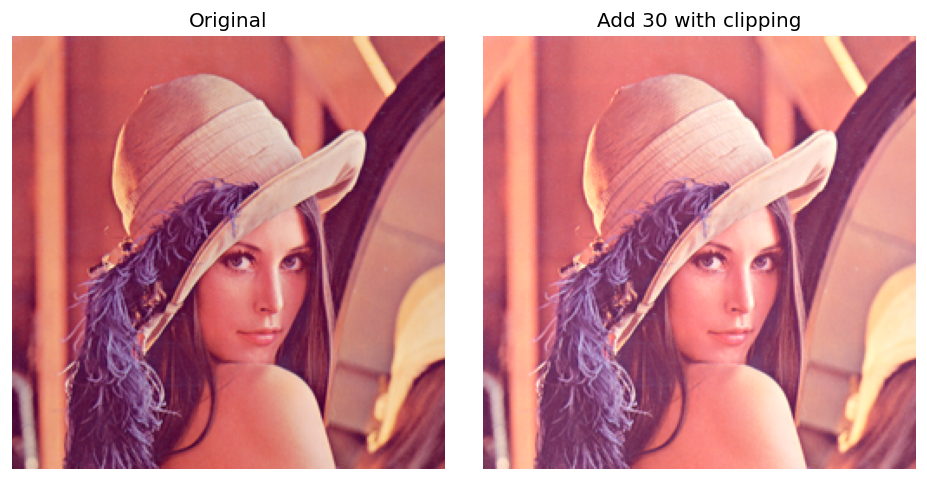

In [3]:
# 셀 3: 밝기 덧셈과 자료형
# 넓은 정수형으로 계산한 뒤 0~255로 제한하여 uint8 값의 순환을 막는다.

# int16에서 밝기를 더하고 0~255로 자른 뒤 uint8로 되돌린다.
bright = np.clip(img.astype(np.int16) + 30, 0, 255).astype(np.uint8)
sample = np.array([240], dtype=np.uint8)
print('uint8 240 + 30:', (sample + np.uint8(30)).tolist())
print('범위 제한:', np.clip(sample.astype(np.int16) + 30, 0, 255).tolist())
panel([('Original', cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
       ('Add 30 with clipping', cv2.cvtColor(bright, cv2.COLOR_BGR2RGB))], cols=2)

## 1.2 색 공간 변환

### BGR와 RGB: 색 성분의 순서

- RGB는 **빨강·초록·파랑** 순서다.
- OpenCV의 일반적인 `IMREAD_COLOR` 로딩 결과는 **파랑·초록·빨강**, 즉 BGR 순서다.
- Matplotlib은 3채널 컬러 배열을 RGB 순서로 해석한다.
- BGR↔RGB는 새로운 색 모델로 바꾸기보다 **채널 순서를 바꾸는 작업**이다.

$$
[B,G,R] \longrightarrow [R,G,B]
$$





- 왼쪽: RGB로 바꿔 정상 표시한 원본이다.
- 오른쪽: BGR 배열을 RGB로 해석해서 빨강과 파랑이 바뀌어 보인다.


> [!warning] 저장과 표시의 순서
> `cv2.imwrite()`에 일반 컬러 영상을 전달할 때는 BGR 배열을 사용한다. Matplotlib에서 정상 표시하려고 만든 RGB 배열을 그대로 전달하면 색이 바뀔 수 있다.

BGR: [125, 130, 205] RGB: [205, 130, 125]


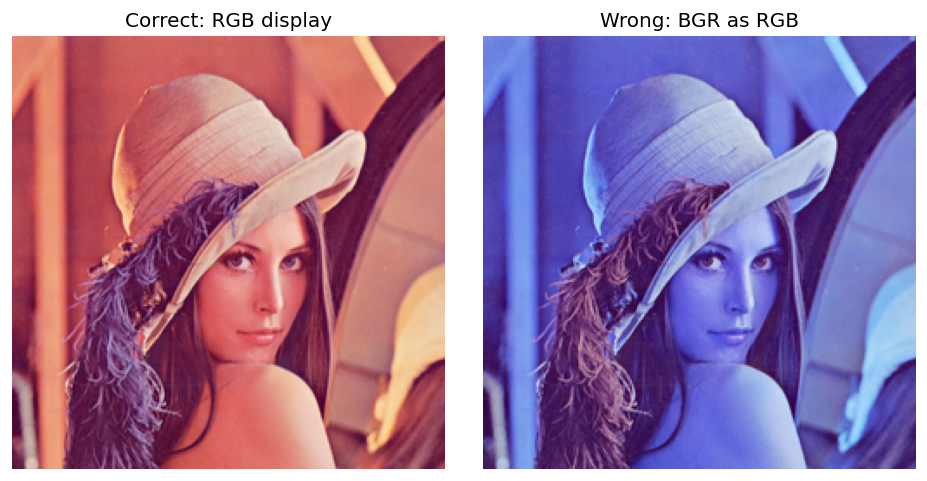

In [4]:
# 셀 4: BGR과 RGB의 표시 차이
# 채널의 수치는 유지하고 순서만 바꾸며, 왕복 변환이 원본과 같은지 확인한다.

# Matplotlib은 RGB 순서로 해석하므로 BGR의 빨강·파랑 위치를 바꾼다.
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
panel([('Correct: RGB display', rgb), ('Wrong: BGR as RGB', img)], cols=2)
print('BGR:', img[y, x].tolist(), 'RGB:', rgb[y, x].tolist())
assert np.array_equal(img, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))

### 그레이스케일: 색을 밝기 한 값으로

8비트 BGR 입력에 대해 OpenCV의 표준 변환은 다음 가중합을 바탕으로 한다.

$$
Y=0.299R+0.587G+0.114B
$$

- 세 채널을 단순히 똑같이 평균내는 방식은 아니다.
- 예를 들어 $R=100$, $G=150$, $B=200$이면 계산값은 $140.75$다. 정수 영상에서는 반올림 등의 처리를 거친 값으로 저장된다.
- 결과는 밝기 하나이므로, 원래 서로 달랐던 색도 같은 Gray 값이 될 수 있다.
- Gray를 3채널로 바꾸어도 잃어버린 원래 색은 복원되지 않는다.

가중합: 151.855
OpenCV Gray: 152 shape: (250, 250)
Gray to RGB: [152, 152, 152]


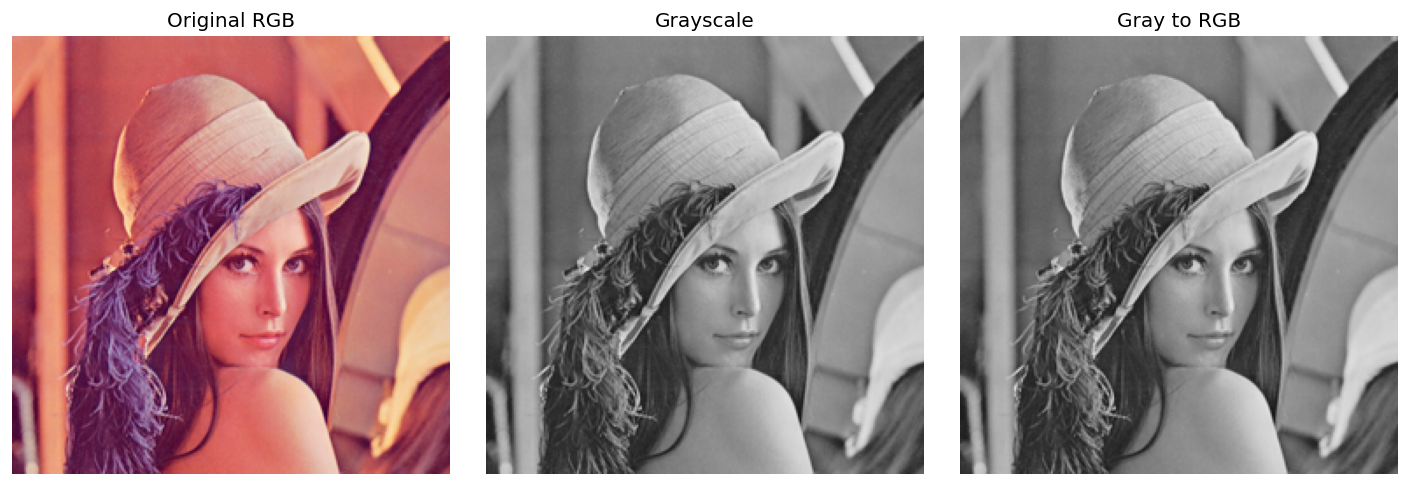

In [5]:
# 셀 5: 그레이스케일 변환
# 색을 가중합으로 밝기 하나로 줄인다. 다시 3채널로 늘려도 원래 색은 복원되지 않는다.

# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Gray 값을 세 채널에 복제한다. 원래의 색 정보가 복원되는 것은 아니다.
gray_rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
panel([('Original RGB', rgb), ('Grayscale', gray), ('Gray to RGB', gray_rgb)])
B, G, R = img[y, x].astype(float)
print('가중합:', 0.299*R + 0.587*G + 0.114*B)
print('OpenCV Gray:', int(gray[y, x]), 'shape:', gray.shape)
print('Gray to RGB:', gray_rgb[y, x].tolist())

### YCrCb: 밝기 성분과 색차 성분 나누기

| 채널 | 쉬운 뜻 | 값 해석 |
| :---: | :---: | :---: |
| Y | 밝기를 나타내는 성분 | 클수록 밝음 |
| Cr | 빨강과 Y의 차이에 기반한 성분 | 128이 색차의 중립 기준 |
| Cb | 파랑과 Y의 차이에 기반한 성분 | 128이 색차의 중립 기준 |

이 문서의 8비트 OpenCV YCrCb 변환은 다음 관계를 사용한다.

$$
\begin{aligned}
Y &= 0.299R+0.587G+0.114B \\
Cr &= 0.713(R-Y)+128 \\
Cb &= 0.564(B-Y)+128
\end{aligned}
$$

- Y는 엄밀히는 **루마(luma)** 성분으로, 물리적으로 측정한 빛의 양 자체는 아니다.
- `128`은 8비트 표현에서 색차를 저장하기 위한 중심값이다. 다른 자료형에 그대로 적용하면 안 된다.
- 일반적으로 YCbCr이라는 이름도 보지만, **OpenCV의 이 변환 결과 순서는 Y, Cr, Cb**다.
- 이 변환의 범위를 모든 영상·방송용 YCbCr 규격에 그대로 적용하지 않는다.





- 세 그림 모두 채널의 **숫자 크기를 회색 밝기로 표시**했다.
- Cr이 밝다고 그 픽셀이 반드시 밝은 빨간색이라는 뜻은 아니다. 다른 성분도 함께 봐야 한다.
- 8비트로 변환하고 되돌릴 때는 반올림과 범위 제한으로 오차가 발생할 수 있다.
- 반면 BGR↔RGB는 값의 순서만 바꾸므로 그대로 되돌릴 수 있다.

YCrCb pixel: [152, 166, 113]
왕복 최대 절대 오차: 1
왕복 평균 절대 오차: 0.377856


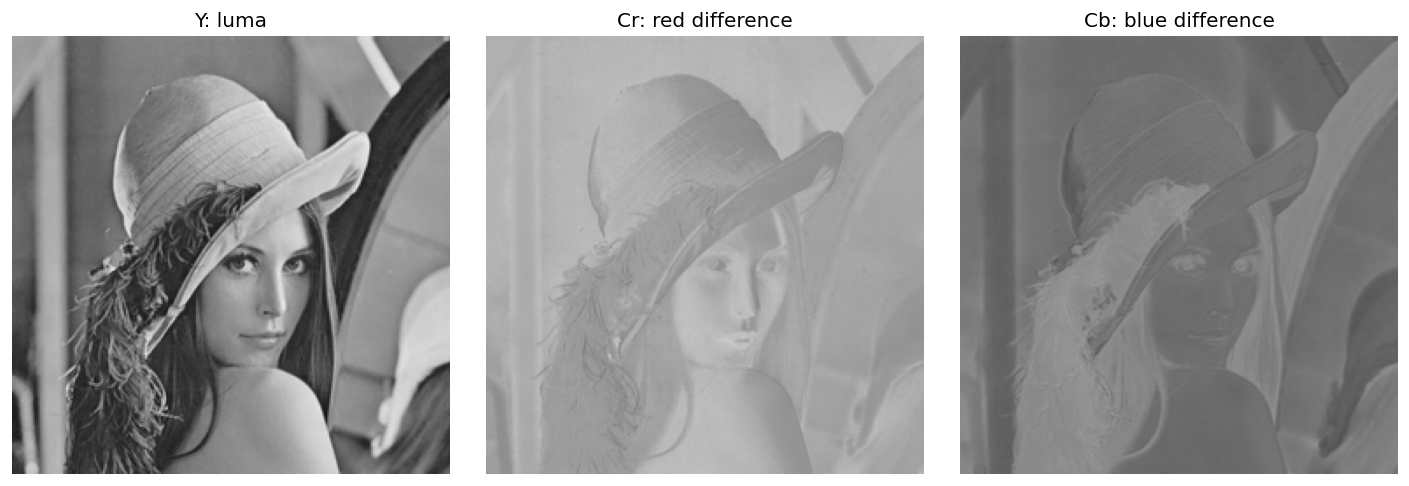

In [6]:
# 셀 6: YCrCb 변환과 왕복 오차
# Y는 밝기 성분, Cr·Cb는 색차 성분이며 8비트 변환에는 반올림 오차가 생길 수 있다.

# 밝기 성분 Y와 색차 성분 Cr·Cb를 분리할 수 있는 표현으로 변환한다.
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
# OpenCV의 반환 순서는 Y, Cr, Cb이다. 각 채널은 높이×너비 배열이다.
Y, Cr, Cb = cv2.split(ycrcb)
back = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)
# uint8끼리 빼면 값이 순환할 수 있어 부호 있는 정수형으로 바꿔 차이를 계산한다.
error = np.abs(img.astype(np.int16) - back.astype(np.int16))
panel([('Y: luma', Y), ('Cr: red difference', Cr), ('Cb: blue difference', Cb)])
print('YCrCb pixel:', ycrcb[y, x].tolist())
print('왕복 최대 절대 오차:', int(error.max()))
print('왕복 평균 절대 오차:', float(error.mean()))

## 1.3 채널 분리와 병합 (Split and Merge)

### 분리: 색 성분별로 한 장씩 꺼내기



$$
I[y,x]=[B[y,x],G[y,x],R[y,x]]
$$

- 입력이 BGR이므로 변수도 `b, g, r` 순서로 받는다.
- 각 결과의 모양은 `(H, W)`다.
- 채널 분리는 색 공간 변환이 아니다. 이미 있는 성분들을 나눠 담는다.



- 위쪽: B·G·R 채널을 각각 **회색으로 표시**했다. 흰 부분은 해당 성분의 값이 크다.
- 아래쪽: 다른 두 성분을 0으로 하여 해당 색으로 표시했다.
- 따라서 B 채널을 회색으로 표시한 그림과 파란색으로 표시한 그림은 같은 B 값을 서로 다른 방식으로 보여준다.

분리한 배열: (250, 250) (250, 250) (250, 250)


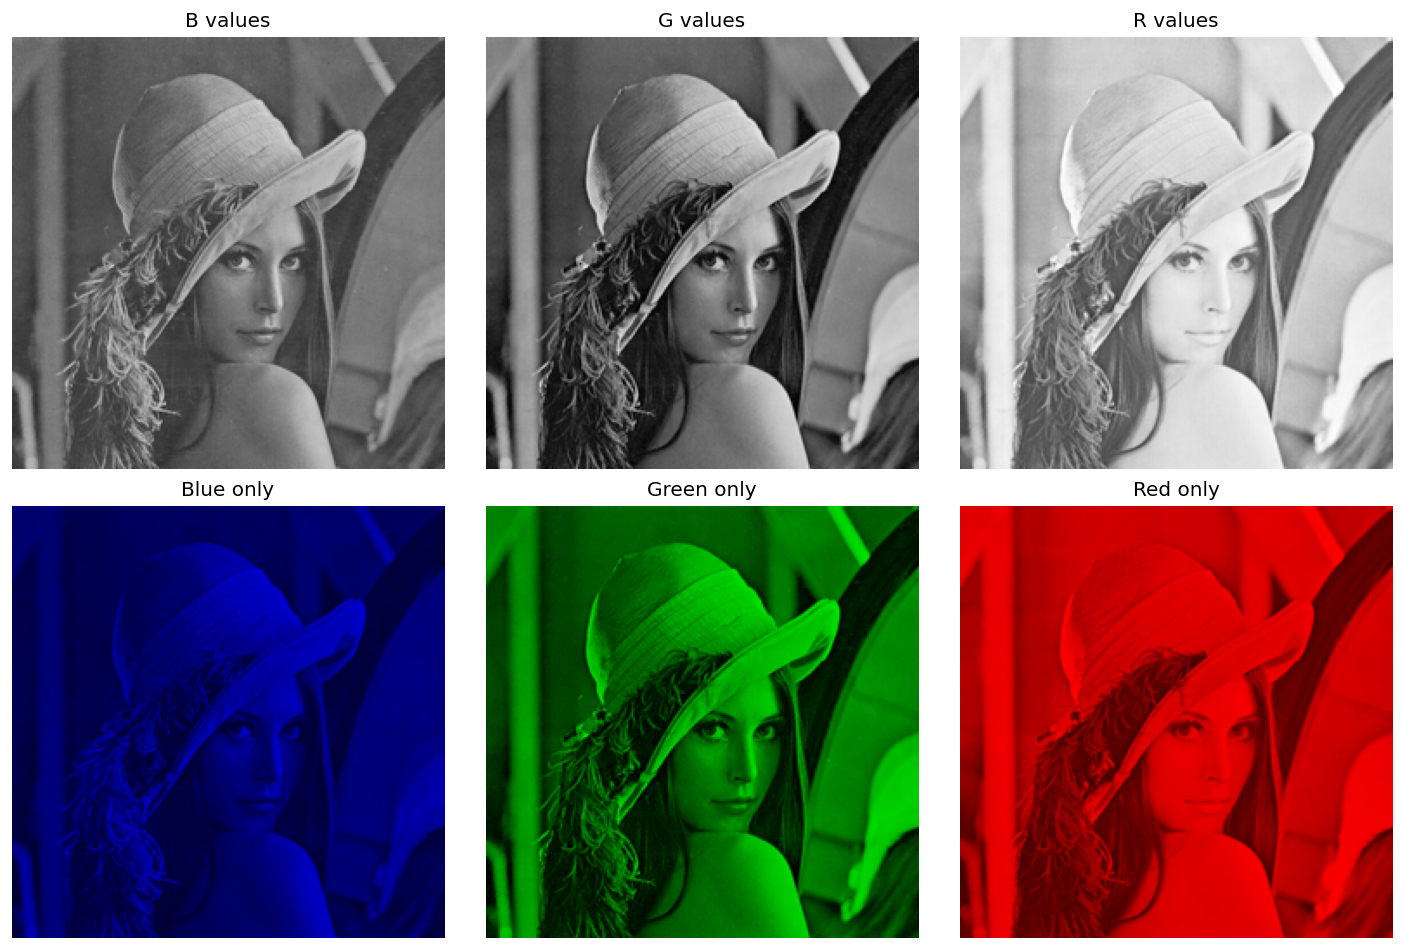

In [7]:
# 셀 7: 채널 분리와 시각화
# 각 성분을 회색으로 표시한 결과와 다른 성분을 0으로 둔 컬러 표시를 비교한다.

# BGR 입력을 파랑·초록·빨강 순서의 세 단일 채널 배열로 분리한다.
b, g, r = cv2.split(img)
zero = np.zeros_like(b)
# 아래 컬러 배열은 Matplotlib에서 표시하므로 RGB 순서다.
panel([('B values', b), ('G values', g), ('R values', r),
       ('Blue only', cv2.merge([zero, zero, b])),
       ('Green only', cv2.merge([zero, g, zero])),
       ('Red only', cv2.merge([r, zero, zero]))])
print('분리한 배열:', b.shape, g.shape, r.shape)

### 병합: 채널을 지정한 순서로 쌓기



- `merge()`는 색 의미를 자동 판단하지 않고 **전달받은 순서대로** 합친다.
- 원본 BGR을 복원하려면 `[b, g, r]` 순서를 유지한다.
- 이 실습에서 병합하는 세 단일 채널은 크기와 자료형이 같아야 한다.
- 분리 후 값을 바꾸지 않고 같은 순서로 병합하면 원본과 정확하게 같다.



### 슬라이싱과 split의 차이



- 채널 하나만 접근할 때는 슬라이싱이 간단하다.
- `cv2.split()`은 채널들을 별도 배열로 분리한다.
- 값을 수정할 때 원본까지 바뀌는지 고려해 선택한다.

같은 순서로 병합하면 원본과 같음: True
순서를 바꾸면 원본과 같음: False
슬라이싱은 메모리 공유: True
copy는 메모리 공유: False
split 결과는 메모리 공유: False


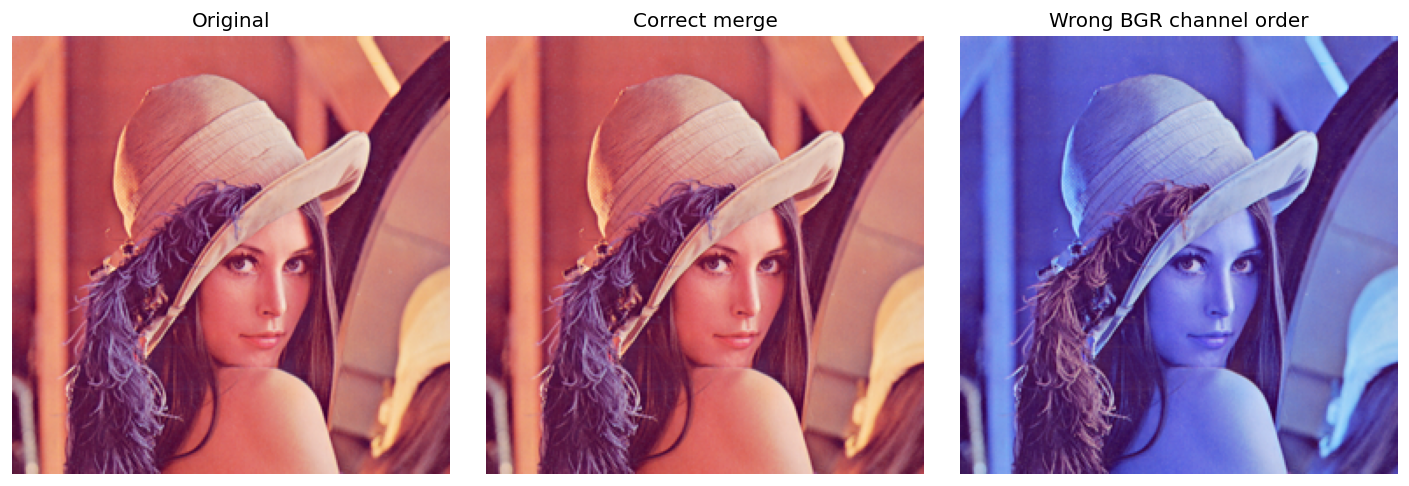

In [8]:
# 셀 8: 채널 병합과 배열의 메모리 공유
# 같은 순서로 병합하면 원본이 복원되고, 슬라이싱 뷰와 copy는 수정 영향이 다르다.

# 분리할 때와 같은 B, G, R 순서로 합쳐 원본 배열을 복원한다.
merged = cv2.merge([b, g, r])
# 채널 순서를 바꾼 비교용 배열이다. merge는 색의 의미를 자동으로 판단하지 않는다.
wrong_order = cv2.merge([r, g, b])
assert np.array_equal(img, merged)
print('같은 순서로 병합하면 원본과 같음:', np.array_equal(img, merged))
print('순서를 바꾸면 원본과 같음:', np.array_equal(img, wrong_order))
# 슬라이싱으로 얻은 뷰는 원본과 메모리를 공유하므로 수정 시 원본도 바뀔 수 있다.
blue_view = img[:, :, 0]
# copy는 별도의 메모리를 만들어 원본에 영향을 주지 않고 수정할 수 있게 한다.
blue_copy = blue_view.copy()
print('슬라이싱은 메모리 공유:', np.shares_memory(img, blue_view))
print('copy는 메모리 공유:', np.shares_memory(img, blue_copy))
print('split 결과는 메모리 공유:', np.shares_memory(img, b))
panel([('Original', rgb), ('Correct merge', cv2.cvtColor(merged, cv2.COLOR_BGR2RGB)),
       ('Wrong BGR channel order', cv2.cvtColor(wrong_order, cv2.COLOR_BGR2RGB))])

### 헷갈리는 작업 비교

| 작업 | 하는 일 | 원본 정보 보존 |
| :---: | :---: | :---: |
| BGR → RGB | 채널 순서 교환 | 보존 |
| BGR → Gray | 세 값을 밝기 하나로 축약 | 색 정보 손실 |
| BGR → YCrCb → BGR | 색 표현 변환 후 복원 | 8비트에서는 오차 가능 |
| split → merge | 성분 분리 후 재조립 | 값과 순서 유지 시 완전 보존 |

## 참고 문서

- [OpenCV — Basic Operations on Images](https://docs.opencv.org/4.x/d3/df2/tutorial_py_basic_ops.html)
- [OpenCV — Color conversions](https://docs.opencv.org/4.x/de/d25/imgproc_color_conversions.html)

## 실행 검증

OpenCV 5.0.0에서 8개 코드 셀을 같은 Python 실행 상태로 순차 실행하여 출력과 그림을 기록했다. Jupyter 커널은 환경의 통신 권한 제한으로 시작되지 않아 Jupyter 전체 실행 자체는 검증하지 못했다.